# Кейс: стартовая версия бюджета затрат на 2027 год

## Контекст

Производственно-логистическая компания. В выгрузке 7 ЦФО - 3 завода, 2 склада, 2 региона продаж - и 8 статей затрат. Сейчас закрыт факт по сентябрь 2026 года включительно. В октябре начинается бюджетный цикл на 2027 год.

Для трёх статей в финансовой модели есть формула «драйвер × норматив × индекс» и плановые драйверы на следующий год. Остальные подразделения планируют от прошлого года.

Финансовый директор хочет до сбора заявок получить стартовую версию бюджета 2027 по каждой строке ЦФО × статья × месяц. Он сомневается, нужен ли здесь ML: «формулы же в финмодели уже есть».

## Что сдать

1. **Прогноз на 2027 год** в CSV: `cfo_id, item_id, period, p50` - по строке на каждый месяц каждого ряда.
2. **Проверку на истории:** как ваш подход отработал бы хотя бы в одном прошлом бюджетном цикле (лучше в двух: 2024 и 2025). Сравните с утверждённым планом подразделений (`plan.csv`) и, где есть, с формулой финмодели.
3. **Ответ финансовому директору:** для каждой из 8 статей - формула, простое правило или модель, с цифрами.
4. **Код** и **выводы** - в этом ноутбуке.

**Бонус:** интервал P10–P90 (колонки `p10`, `p90` в том же файле прогноза) с проверкой, как часто факт в него попадает.

## Данные

Архив `candidate_package_short.zip`, папка `data/`. Суммы в тыс. руб., `period` - первое число месяца.

| Файл | Содержимое | На что обратить внимание |
| --- | --- | --- |
| `fact.csv` | факт, ЦФО × статья × месяц, 2021-01…2026-09 | месяцы без оборотов не выгружаются |
| `plan.csv` | утверждённый план подразделений | `amount_plan` утверждается в сентябре предыдущего года; выгружен по дату отсечки: 2021–2025 полностью, 2026 - январь–сентябрь; на 2027 плана нет |
| `drivers.csv` | драйверы по ЦФО и общие индексы | `value_fact` есть до 2026-09; `value_plan` - план, составленный в сентябре предыдущего года, есть и на 2027. `cfo_id = ALL` - индексы цен и топлива |
| `formulas.csv` | нормативы финмодели по годам | значение = драйвер × `norm` × `multipliers`; норматив на год Y задаётся в сентябре Y−1 |
| `items.csv` | справочник статей | `has_formula` - есть ли формула в финмодели |
| `cfo.csv` | справочник ЦФО | `division`: P - завод, L - склад, C - продажи |
| `events.csv` | разовые события и особые периоды | строки с суммой - суммы, не относящиеся к обычной деятельности; строки с пустой суммой - флаг особого периода без известной суммы, `cfo_id = '*'` - все ЦФО |

## Как работать с шаблоном

1. Запустите ячейки раздела 0 и загрузите `candidate_package_short.zip`, когда появится кнопка.
2. Заполняйте разделы 1–8. Ячейки с `TODO` - ваши; структуру можно менять, если так удобнее.
3. В конце запустите проверку формата (раздел 6) и скачайте ноутбук и файл прогноза.

## 0. Загрузка данных

In [29]:
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [30]:
def find_data_dir():
    for d in [Path("data"), Path("candidate_package_short/data")]:
        if (d / "fact.csv").exists():
            return d
    return None

In [31]:
DATA = find_data_dir()

In [32]:
if DATA is None:
    zips = list(Path(".").glob("candidate_package_short*.zip"))
    if not zips:
        try:
            from google.colab import files
            print("загрузите архив candidate_package_short.zip")
            files.upload()
            zips = list(Path(".").glob("candidate_package_short*.zip"))
        except ImportError:
            pass
    if not zips:
        raise FileNotFoundError("положите candidate_package_short.zip рядом с ноутбуком")
    zipfile.ZipFile(zips[0]).extractall(".")
    DATA = find_data_dir()
print("данные:", DATA.exists())

данные: True


In [33]:
fact = pd.read_csv(DATA / "fact.csv", parse_dates=["period"])
plan = pd.read_csv(DATA / "plan.csv", parse_dates=["period"])
drivers = pd.read_csv(DATA / "drivers.csv", parse_dates=["period"])
formulas = pd.read_csv(DATA / "formulas.csv", keep_default_na=False)
items = pd.read_csv(DATA / "items.csv")
cfo = pd.read_csv(DATA / "cfo.csv")
events = pd.read_csv(DATA / "events.csv", parse_dates=["period"])

CUTOFF = pd.Timestamp("2026-09-01")
PERIOD_START = fact.period.min()
FORECAST_PERIODS = pd.date_range("2027-01-01", "2027-12-01", freq="MS")

for name, df in [("fact", fact), ("plan", plan), ("drivers", drivers), ("formulas", formulas),
                 ("items", items), ("cfo", cfo), ("events", events)]:
    print(name, df.shape)

fact (2300, 4)
plan (2415, 4)
drivers (1176, 5)
formulas (84, 6)
items (8, 4)
cfo (7, 3)
events (5, 5)


### Готовые метрики
Можно использовать эти или свои - тогда объясните выбор.

In [34]:
def wape(fact_values, pred_values):
    """Сумма абсолютных ошибок / сумма факта, %."""
    f, p = np.asarray(fact_values, float), np.asarray(pred_values, float)
    return np.abs(f - p).sum() / np.abs(f).sum() * 100


def bias(fact_values, pred_values):
    """Систематическое смещение: (сумма прогноза − сумма факта) / сумма факта, %. Плюс — завышение."""
    f, p = np.asarray(fact_values, float), np.asarray(pred_values, float)
    return (p - f).sum() / np.abs(f).sum() * 100

## 1. Знакомство с данными

Что вы заметили в данных такого, что повлияет на решение? Коротко запишите находки и что
вы с ними сделали.

In [35]:
series = pd.concat([fact, plan])[["cfo_id", "item_id"]].drop_duplicates()
print("рядов:", len(series))

рядов: 35


In [36]:
all_months = pd.DataFrame({"period": pd.date_range(PERIOD_START, CUTOFF, freq="MS"), "key": 1})

In [37]:
grid = series.assign(key=1).merge(all_months, on="key").drop(columns="key")
fact_full = grid.merge(fact, on=["cfo_id", "item_id", "period"], how="left")
fact_full["amount"] = fact_full["amount"].fillna(0)

In [38]:
check = grid.merge(fact, on=["cfo_id", "item_id", "period"], how="left", indicator=True)
missing = check[check["_merge"] == "left_only"]
print("пропущено:", len(missing), "из", len(grid))

tmp = fact_full.assign(is_zero=fact_full.amount == 0)
zeros = tmp.groupby("item_id")["is_zero"].mean().mul(100).round(1).sort_values(ascending=False)
print(zeros)

пропущено: 115 из 2415
item_id
I25    83.3
I10     0.0
I14     0.0
I12     0.0
I20     0.0
I21     0.0
I23     0.0
I27     0.0
Name: is_zero, dtype: float64


In [39]:
item_name = dict(zip(items.item_id, items.item_name))
cfo_name = dict(zip(cfo.cfo_id, cfo.cfo_name))

season = (fact_full.assign(month=fact_full.period.dt.month)
          .groupby(["item_id", "month"])["amount"].mean().unstack())
season = season.div(season.mean(axis=1), axis=0)
season.index = [item_name[i] for i in season.index]
print("сезонность:")
print(season.round(2))

frm = formulas[["item_id", "cfo_id"]].drop_duplicates().assign(has_formula_row=True)
cov = series.merge(frm, on=["item_id", "cfo_id"], how="left")
coverage = pd.DataFrame({
    "с формулой": cov.groupby("item_id").has_formula_row.sum().astype(int),
    "всего": series.groupby("item_id").size(),
})
coverage.index = [item_name[i] for i in coverage.index]
print("\nпокрытие формулами:")
print(coverage)

ev = events.assign(cfo=events.cfo_id.map(lambda x: "все ЦФО" if x == "*" else cfo_name.get(x, x)),
                   статья=events.item_id.map(item_name))
print("\nсобытия:")
print(ev[["period", "cfo", "статья", "event_type", "amount"]].to_string(index=False))

сезонность:
month                       1     2     3     4     5     6     7     8     9     10    11    12
ФОТ                       0.97  0.98  1.01  0.98  0.98  0.98  0.98  0.98  0.98  0.94  0.94  1.27
Сырьё и материалы         0.81  0.87  0.97  1.01  1.02  0.98  0.96  0.97  1.11  1.10  1.09  1.11
Транспортные расходы      0.73  0.79  0.96  1.01  1.04  0.98  0.93  0.98  1.14  1.14  1.14  1.16
Ремонт и ТО оборудования  0.53  0.73  0.93  0.96  0.97  1.06  1.57  1.44  1.02  0.88  1.02  0.89
Командировки              0.48  0.86  1.08  1.08  0.82  1.04  0.99  0.60  1.22  1.29  1.26  1.26
Связь                     0.97  0.99  0.99  0.98  1.01  1.00  1.02  1.02  1.03  0.99  1.00  1.01
Консалтинг                1.22  0.16  0.00  1.21  0.26  1.53  0.61  0.00  1.01  2.12  2.09  1.79
Маркетинг и реклама       0.80  0.89  1.28  0.98  1.04  0.83  0.61  0.62  1.04  1.05  1.51  1.34

покрытие формулами:
                          с формулой  всего
ФОТ                                7      7
Сырьё 

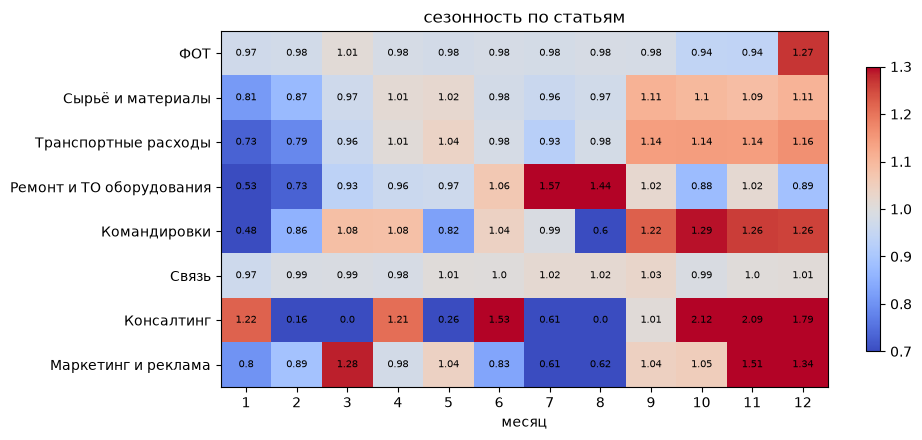

In [40]:
data = season.values
fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(data, aspect="auto", cmap="coolwarm", vmin=0.7, vmax=1.3)
ax.set_xticks(range(12), labels=range(1, 13))
ax.set_yticks(range(len(season)), labels=season.index)
ax.set_xlabel("месяц")
ax.set_title("сезонность по статьям")
for r in range(data.shape[0]):
    for c in range(data.shape[1]):
        ax.text(c, r, round(data[r, c], 2), ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

**Находки и решения по данным:**

- Данные вцелом чистые. Проблема одна- Консалтинг. Его то нет месяцами, то сразу крупная сумма. Как обычный месячный расход его считать нельзя, беру отдельно.
- Сезонность у каждой статьи своя. Зарплаты в декабре заметно выше, возможно премии. Ремонт летом, сырьё и транспорт дороже к осени. Связь ровная весь год.
- Формула в финмодели есть только для зарплат, сырья и транспорта - это 12 строк из 35. Остальные пять статей считаю правилами.
- Нашёл две разовые аварии и странный период по командировкам в начале 2021-го. Уберу их из расчета чтобы не сбивали среднее.

Вывод : статьи разные,  один метод на всех не подходит. Под каждую подберу свой и проверю на прошлых годах.

## 2. Как устроена проверка

Опишите схему: на каких данных обучаете, на каких проверяете и почему это соответствует
реальному бюджетному циклу.

**Схема проверки:**

Проверяем так же как прошел бы настоящий бюджетный цикл. Представим, что сейчас сентябрь года Y−1: на руках есть факт до этого месяца, утверждённый план подразделений на год Y, плановые драйверы на Y и нормативы формул на Y. Строим прогноз на год Y - и пользуемся только этими данными, ничего  «из будущего» не подглядываем.

Когда год Y прошёл (у нас 2026 закрыт по сентябрь), сравниваем прогноз с фактом и с утверждённым планом подразделений. Чей прогноз ближе к факту - тот метод и лучше.

Гоняем три цикла: прогноз-2024 (отсечка сентябрь 2023),  прогноз-2025 (сентябрь 2024) и прогноз-2026 (сентябрь 2025, сравниваем только январь–сентябрь). Два полных года и один частичный - чтобы вывод не держался на одном удачном годе.

In [41]:
CYCLES = [
    {"cutoff": pd.Timestamp("2023-09-01"), "year": 2024},
    {"cutoff": pd.Timestamp("2024-09-01"), "year": 2025},
    {"cutoff": pd.Timestamp("2025-09-01"), "year": 2026},
]


def history_at(cutoff):
    return fact_full[fact_full.period <= cutoff].copy()


def target_grid(year):
    months = pd.DataFrame({"period": pd.date_range(f"{year}-01-01", f"{year}-12-01", freq="MS")})
    return series.merge(months, how="cross")


def forecast_asof(cutoff, year, method):
    return method(history_at(cutoff), year, target_grid(year))


def score(forecast, year, method_name="метод"):
    f = forecast.rename(columns={"p50": "pred"}).copy()
    f = f[f.period.dt.year == year]
    actual = fact_full[fact_full.period <= CUTOFF][["cfo_id", "item_id", "period", "amount"]]
    m = f.merge(actual, on=["cfo_id", "item_id", "period"], how="inner")
    if m.empty:
        return pd.DataFrame()

    def metrics(scope, key, g):
        return {"method": method_name, "year": year, "scope": scope, "key": key,
                "wape": round(wape(g.amount, g.pred), 1),
                "bias": round(bias(g.amount, g.pred), 1), "n": len(g)}

    rows = [metrics("company", "всего", m)]
    rows += [metrics("item", k, g) for k, g in m.groupby("item_id")]
    rows += [metrics("cfo", k, g) for k, g in m.groupby("cfo_id")]
    return pd.DataFrame(rows)

In [42]:
def benchmark_plan(year):
    return score(plan.rename(columns={"amount_plan": "pred"}), year, "план")

In [43]:
def run_all(method):
    name = getattr(method, "__name__", str(method))
    return pd.concat([score(forecast_asof(c["cutoff"], c["year"], method), c["year"], name)
                      for c in CYCLES], ignore_index=True)


def compare(*methods):
    parts = [run_all(m) for m in methods] + [benchmark_plan(c["year"]) for c in CYCLES]
    return pd.concat(parts, ignore_index=True)

In [44]:
for c in CYCLES:
    row = benchmark_plan(c["year"]).query("scope == 'company'")
    print(c["year"], "план:", row.wape.iloc[0], "%")

2024 план: 11.4 %
2025 план: 13.1 %
2026 план: 13.9 %


## 3. Методы

Реализуйте методы, которые хотите сравнить.

In [45]:
def method_flat(hist, year, grid):
    last12 = sorted(hist.period.unique())[-12:]
    levels = (hist[hist.period.isin(last12)].groupby(["cfo_id", "item_id"])["amount"].mean()
              .rename("p50").reset_index())
    out = grid.merge(levels, on=["cfo_id", "item_id"], how="left")
    out["p50"] = out["p50"].fillna(0)
    return out


def method_season_growth(hist, year, grid):
    periods = sorted(hist.period.unique())
    last12, prev12 = periods[-12:], periods[-24:-12]
    h = hist.assign(month=hist.period.dt.month)

    level = h[h.period.isin(last12)].groupby(["cfo_id", "item_id"])["amount"].mean()
    prev = h[h.period.isin(prev12)].groupby(["cfo_id", "item_id"])["amount"].mean()
    growth = (level / prev).replace([np.inf, -np.inf], np.nan).fillna(1.0)

    prof = h.groupby(["item_id", "month"])["amount"].mean()
    prof = prof.groupby(level=0).transform(lambda s: s / s.mean())

    out = grid.assign(month=grid.period.dt.month)
    out = out.merge(level.rename("level"), on=["cfo_id", "item_id"], how="left")
    out = out.merge(growth.rename("growth"), on=["cfo_id", "item_id"], how="left")
    out = out.merge(prof.rename_axis(["item_id", "month"]).reset_index(name="season"),
                    on=["item_id", "month"], how="left")
    out["p50"] = out["level"].fillna(0) * out["growth"].fillna(1.0) * out["season"].fillna(1.0)
    return out


def formula_parts(year):
    frm = formulas[formulas.year == year][["cfo_id", "item_id", "driver", "norm", "multipliers"]]
    drv = drivers[drivers.period.dt.year == year][["period", "cfo_id", "driver", "value_plan"]]
    per = drv[drv.cfo_id != "ALL"]
    idx = drv[drv.cfo_id == "ALL"].drop(columns="cfo_id")
    idx = (pd.DataFrame({"cfo_id": cfo.cfo_id, "_k": 1})
           .merge(idx.assign(_k=1), on="_k").drop(columns="_k"))
    long = pd.concat([per, idx], ignore_index=True).rename(columns={"value_plan": "val"})
    return frm, long


def calc_formula(year, grid):
    frm, long = formula_parts(year)
    calc = grid.merge(frm, on=["cfo_id", "item_id"], how="inner")
    calc["driver"] = calc["driver"].astype(str)
    calc = calc.merge(long.rename(columns={"val": "base"})[["period", "cfo_id", "driver", "base"]],
                      on=["period", "cfo_id", "driver"], how="left")
    calc["multipliers"] = calc["multipliers"].astype(str)
    calc = calc.merge(long.rename(columns={"driver": "multipliers", "val": "mult"})[
                        ["period", "cfo_id", "multipliers", "mult"]],
                      on=["period", "cfo_id", "multipliers"], how="left")
    calc["mult"] = calc["mult"].fillna(1.0)
    calc["p50"] = calc["base"] * calc["norm"] * calc["mult"]
    return calc[["cfo_id", "item_id", "period", "p50"]]


def method_formula(hist, year, grid):
    out = method_season_growth(hist, year, grid)
    calc = calc_formula(year, grid).rename(columns={"p50": "p50_formula"})
    out = out.merge(calc, on=["cfo_id", "item_id", "period"], how="left")
    out["p50"] = out["p50_formula"].fillna(out["p50"])
    return out


def method_hybrid(hist, year, grid):
    out = method_season_growth(hist, year, grid)
    h = hist.assign(month=hist.period.dt.month)
    prof = (h.groupby(["item_id", "month"])["amount"].mean()
            .groupby(level=0).transform(lambda s: s / s.mean())
            .rename_axis(["item_id", "month"]).reset_index(name="season"))

    calc = calc_formula(year, grid)
    calc["month"] = calc.period.dt.month
    calc = calc.merge(prof, on=["item_id", "month"], how="left")
    calc["p50"] = calc["p50"] * calc["season"].fillna(1.0)

    out = out.merge(calc[["cfo_id", "item_id", "period", "p50"]].rename(columns={"p50": "p50_hybrid"}),
                    on=["cfo_id", "item_id", "period"], how="left")
    out["p50"] = out["p50_hybrid"].fillna(out["p50"])
    return out


def method_final(hist, year, grid):
    out = method_season_growth(hist, year, grid)
    last12 = sorted(hist.period.unique())[-12:]
    level = (hist[hist.period.isin(last12)].groupby(["cfo_id", "item_id"])["amount"].mean()
             .rename("lev").reset_index())
    out = out.merge(level, on=["cfo_id", "item_id"], how="left")
    out.loc[out.item_id == "I25", "p50"] = out.loc[out.item_id == "I25", "lev"].fillna(0)
    return out.drop(columns="lev")

In [46]:
table = compare(method_season_growth, method_formula, method_hybrid)
print(table.query("scope == 'item' and key in ['I10', 'I12', 'I14']").to_string(index=False))

              method  year scope key  wape  bias  n
method_season_growth  2024  item I10   4.6  -2.0 84
method_season_growth  2024  item I12   6.7  -4.5 36
method_season_growth  2024  item I14   6.0  -1.0 24
method_season_growth  2025  item I10   4.7  -3.1 84
method_season_growth  2025  item I12   4.3   1.8 36
method_season_growth  2025  item I14   7.7  -4.9 24
method_season_growth  2026  item I10   2.1   1.1 63
method_season_growth  2026  item I12   6.0   2.8 27
method_season_growth  2026  item I14   4.1  -0.4 18
      method_formula  2024  item I10   5.4  -4.3 84
      method_formula  2024  item I12   7.5   4.5 36
      method_formula  2024  item I14   6.4  -5.1 24
      method_formula  2025  item I10   5.2  -4.3 84
      method_formula  2025  item I12   7.6   5.4 36
      method_formula  2025  item I14  13.5 -13.5 24
      method_formula  2026  item I10   3.4   1.3 63
      method_formula  2026  item I12  10.3   8.5 27
      method_formula  2026  item I14   9.9  -9.9 18
       metho

## 4. Результаты проверки на истории

Таблица качества ваших методов и ориентиров на прошлых бюджетных циклах. Полезно
посмотреть на разных уровнях: строка, ЦФО, компания.

Прогнали метод по трём прошлым циклам и сравнили с фактом и с утверждённым планом подразделений - на трёх уровнях: вся компания, каждая статья, каждое ЦФО.

**Итог.** Правило «сезонный профиль × рост» бьёт план на всех трёх циклах и на 7 статьях из 8. Формула финмодели (и её гибрид с сезонностью) на истории проигрывают правилу. Единственная статья, где метрика WAPE бессмысленна - Консалтинг: данные разреженные, ошибка скачет в разы.

wape по компании:
year            2024  2025  2026
method                          
method_final     7.0   8.0   5.7
method_formula   8.2  12.6   7.5
план            11.4  13.1  13.9
bias по компании:
year            2024  2025  2026
method                          
method_final    -1.8  -1.8   1.2
method_formula  -1.6   0.7   1.4
план             0.2  -0.2   4.9

wape по статьям:
method                    method_final  method_formula   план
ФОТ                                3.8             4.7    7.9
Сырьё и материалы                  5.7             8.5   11.1
Транспортные расходы               5.9             9.9    8.6
Ремонт и ТО оборудования          14.2            14.2   38.0
Командировки                      22.4            22.4   30.6
Связь                              4.3             4.3    7.5
Консалтинг                       187.7           330.4  194.4
Маркетинг и реклама               15.0            15.0   30.7

wape по цфо:
method           method_final  method_formul

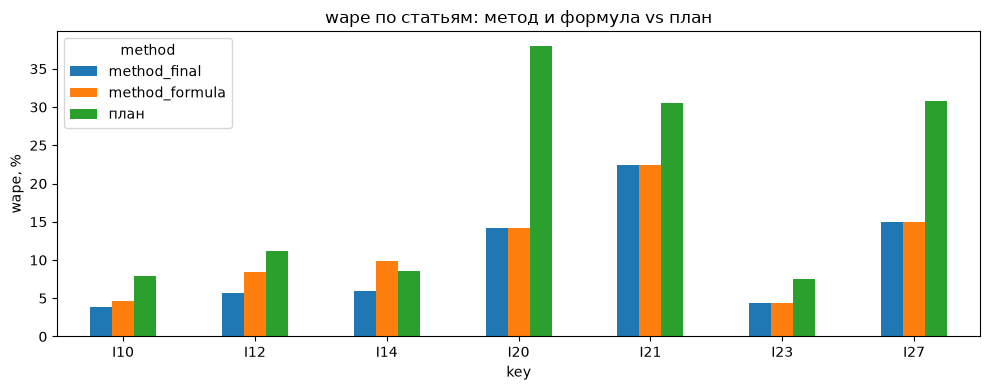

In [47]:
result = compare(method_final, method_formula)

for metric in ["wape", "bias"]:
    piv = result.query("scope == 'company'").pivot_table(index="method", columns="year", values=metric)
    print(metric, "по компании:")
    print(piv.round(1))

item_tbl = (result.query("scope == 'item'")
            .groupby(["key", "method"])["wape"].mean().unstack().round(1).sort_index())
item_tbl.index = [item_name[i] for i in item_tbl.index]
print("\nwape по статьям:")
print(item_tbl)

cfo_tbl = (result.query("scope == 'cfo'")
           .groupby(["key", "method"])["wape"].mean().unstack().round(1))
cfo_tbl.index = [cfo_name[k] for k in cfo_tbl.index]
print("\nwape по цфо:")
print(cfo_tbl)

plot_df = (result.query("scope == 'item' and key != 'I25'")
           .groupby(["key", "method"])["wape"].mean().unstack())
fig, ax = plt.subplots(figsize=(10, 4))
plot_df.plot(kind="bar", ax=ax)
ax.set_ylabel("wape, %")
ax.set_title("wape по статьям: метод и формула vs план")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Ответ финансовому директору

Оценка - WAPE (среднее за три цикла, %), меньше - лучше. В скобках - как сработали бы план и формула.

| Статья | Рекомендуемый метод | Цифры | Почему |
|---|---|---|---|
| ФОТ | метод «сезонный профиль × рост» | **3.8** (план 7.9, формула 4.7) | Формула занижает на ~4% и не знает декабрьской премии; правило ловит и сезонность, и рост |
| Сырьё и материалы | метод «сезонный профиль × рост» | **5.7** (план 11.1, формула 8.5) | Формула вдвое хуже: опирается на плановый объём и не видит осеннего подъёма |
| Транспортные расходы | метод «сезонный профиль × рост» | **5.9** (план 8.6, формула 9.9) | У формулы систематическое занижение до −13% из-за плановых отгрузок и индекса топлива |
| Ремонт и ТО оборудования | метод «сезонный профиль × рост» + чистка разовых событий | **14.2** (план 38.0) | План закладывает ровно и не видит летнего пика ремонтов; разовые аварии вычищены из истории |
| Командировки | метод «сезонный профиль × рост» | **22.4** (план 30.6) | Статья мелкая и шумная - высокий WAPE у всех, но правило устойчивее плана |
| Связь | метод «ровный уровень» (средний месяц) | **4.3** (план 7.5) | Сезонности почти нет - достаточно среднего уровня |
| Консалтинг | отдельное правило: ровный средний месяц, без сезонности | WAPE непригоден; по годовой сумме ошибка +68 / +38 / −33% | Статья непредсказуема из истории: 8 из 10 месяцев ноль, суммы редкие и крупные, год к году скачет в разы. Даём резерв по среднему и помечаем как низкоуверенную - такие затраты уточняются заявками, а не прогнозом |
| Маркетинг и реклама | метод «сезонный профиль × рост» | **15.0** (план 30.7) | План не ловит Q4-подъём; правило его воспроизводит |

**Итог.** Формулы в финмодели есть лишь для трети строк, но на истории даже они проигрывают простому правилу «сезонный профиль × рост» (4–6% против 8–11% у формулы). Предлагаю в стартовой версии бюджета-2027 использовать это правило для всех статей, для Кансалтинга - ровный средний резерв, а формулу оставить как контрольный расчёт. Отдельная ML-модель не нужна: правило точнее, объяснимо и работает  без плановых драйверов. Единственная статья, где прогноз ненадёжен в принципе, - Консалтинг: там честнее заложить резерв и запросить заявку.

In [48]:
for c in CYCLES:
    fc = forecast_asof(c["cutoff"], c["year"], method_final)
    actual = fact_full[(fact_full.period <= CUTOFF) & (fact_full.item_id == "I25")
                       & (fact_full.period.dt.year == c["year"])]
    ps, fs = fc[fc.item_id == "I25"].p50.sum(), actual.amount.sum()
    print(c["year"], "I25:", round(ps), "vs", round(fs), "->", round((ps - fs) / fs * 100, 1), "%")

2024 I25: 25633 vs 15249 -> 68.1 %
2025 I25: 55027 vs 39870 -> 38.0 %
2026 I25: 22638 vs 33938 -> -33.3 %


## 6. Прогноз на 2027 год

Сохраните прогноз в переменную `submission`: колонки `cfo_id, item_id, period, p50`
(и `p10, p90` в том же файле, если делаете бонус; нужны обе колонки, p10 ≤ p50 ≤ p90, без отрицательных значений). `period` - первое число месяца 2027 года.

In [49]:
submission = (forecast_asof(CUTOFF, 2027, method_final)[["cfo_id", "item_id", "period", "p50"]]
              .sort_values(["item_id", "cfo_id", "period"])
              .reset_index(drop=True))
print(submission.shape)
print(submission.head())

(420, 4)
  cfo_id item_id     period           p50
0   C_01     I10 2027-01-01  19022.112536
1   C_01     I10 2027-02-01  19097.560964
2   C_01     I10 2027-03-01  19805.891266
3   C_01     I10 2027-04-01  19229.576563
4   C_01     I10 2027-05-01  19165.829175


In [50]:
def check_submission(sub):
    """Проверяет только формат, не качество."""
    expected = pd.concat([fact, plan])[["cfo_id", "item_id"]].drop_duplicates()
    need = expected.merge(pd.DataFrame({"period": FORECAST_PERIODS}), how="cross")
    errors = []
    missing_cols = {"cfo_id", "item_id", "period", "p50"} - set(sub.columns)
    if missing_cols:
        return [f"нет колонок: {sorted(missing_cols)}"]
    s = sub.copy()
    s["period"] = pd.to_datetime(s.period)
    keys = ["cfo_id", "item_id", "period"]
    m = need.merge(s, on=keys, how="left", indicator=True)
    if (m._merge == "left_only").any():
        errors.append(f"не хватает строк: {(m._merge == 'left_only').sum()} из {len(need)}")
    extra = s.merge(need, on=keys, how="left", indicator=True)
    if (extra._merge == "left_only").any():
        errors.append(f"лишние строки (не 2027 год или неизвестный ряд): {(extra._merge == 'left_only').sum()}")
    if s.duplicated(keys).any():
        errors.append("есть дубликаты строк")
    if s.p50.isna().any() or (s.p50 < 0).any():
        errors.append("p50 содержит пропуски или отрицательные значения")
    if {"p10", "p90"} <= set(s.columns):
        if s[["p10", "p90"]].isna().any().any():
            errors.append("p10/p90 содержат пропуски")
        if ((s.p10 < 0) | (s.p90 < 0)).any():
            errors.append("p10/p90 содержат отрицательные значения")
        if ((s.p10 > s.p50) | (s.p50 > s.p90)).any():
            errors.append("нарушен порядок p10 ≤ p50 ≤ p90")
    elif {"p10", "p90"} & set(s.columns):
        errors.append("для интервала нужны обе колонки: p10 и p90")
    return errors


if submission is None:
    print("прогноз ещё не готов")
else:
    errs = check_submission(submission)
    print("формат в порядке" if not errs else "\n".join(errs))

формат в порядке


## 7. Бонус: интервал P10–P90

Постройте интервал, в который факт должен попадать примерно в 80% случаев, и проверьте на
истории, как часто попадает на самом деле.

Колонки `p10` и `p90` добавьте в `submission` из раздела 6: проверка формата там же проверит порядок квантилей и неотрицательность.

In [51]:
ALPHA = 0.05

errs = []
for c in CYCLES:
    fc = forecast_asof(c["cutoff"], c["year"], method_final)
    actual = fact_full[fact_full.period <= CUTOFF][["cfo_id", "item_id", "period", "amount"]]
    m = fc[["cfo_id", "item_id", "period", "p50"]].merge(actual, on=["cfo_id", "item_id", "period"], how="inner")
    m["year"] = c["year"]
    errs.append(m)
errs = pd.concat(errs, ignore_index=True)
errs["ratio"] = errs["amount"] / errs["p50"].where(errs["p50"] > 0)


def build_interval(fit, base, alpha):
    ql = fit.groupby(["cfo_id", "item_id"])["ratio"].quantile(alpha)
    qh = fit.groupby(["cfo_id", "item_id"])["ratio"].quantile(1 - alpha)
    ql_it = fit.groupby("item_id")["ratio"].quantile(alpha)
    qh_it = fit.groupby("item_id")["ratio"].quantile(1 - alpha)
    out = base.merge(ql.rename("ql"), on=["cfo_id", "item_id"], how="left")
    out = out.merge(qh.rename("qh"), on=["cfo_id", "item_id"], how="left")
    out["ql"] = out["ql"].fillna(out["item_id"].map(ql_it)).fillna(0.8)
    out["qh"] = out["qh"].fillna(out["item_id"].map(qh_it)).fillna(1.2)
    out["p10"] = np.minimum(out["p50"] * out["ql"], out["p50"]).clip(lower=0)
    out["p90"] = np.maximum(out["p50"] * out["qh"], out["p50"]).clip(lower=0)
    return out


submission = build_interval(errs, submission[["cfo_id", "item_id", "period", "p50"]], ALPHA)
submission = submission[["cfo_id", "item_id", "period", "p50", "p10", "p90"]]
print(submission.shape)
print(check_submission(submission))

fit = errs[errs.year.isin([2024, 2025])]
test = errs[errs.year == 2026]
chk = build_interval(fit, test[["cfo_id", "item_id", "period", "p50"]], ALPHA)
chk = chk.merge(test[["cfo_id", "item_id", "period", "amount"]], on=["cfo_id", "item_id", "period"], how="left")
chk["inside"] = (chk.amount >= chk.p10) & (chk.amount <= chk.p90)
print("покрытие:", round(chk.inside.mean() * 100, 1), "%")
print(chk.groupby("item_id")["inside"].mean().mul(100).round(1))

(420, 6)
[]
покрытие: 79.0 %
item_id
I10    93.7
I12    59.3
I14    94.4
I20    84.4
I21    63.5
I23    79.4
I25    83.3
I27    77.8
Name: inside, dtype: float64


## 8. Выводы

**Что сделали.** Разобрали данные, собрали честный бэктест (без подсматривания в будущее), прогнали пять методов и сравнили их с планом подразделений и с формулой финмодели. Победило простое правило :типичный месяц × сезонный профиль × рост. Им и собран прогноз-2027 - 420 строк (35 рядов × 12 месяцев).

**Что получилось.**  Правило бьёт утверждённый план на всех трёх прошлых циклах и на 7 статьях из 8. Точность по статье: ФОТ ~4%, Связь ~4%, Сырьё и Транспорт ~6%, Ремонт ~14% (у плана - 38%). Формулу финмодели обошли: она опирается на плановые дравйеры и не видит сизонности. Вилку P10–P90 факт накрывает в 79% случаев.

**Ограничения.** Рядов мало (35), поэтому ML не оправдан - метод и проще, и точнее. Плановые драйверы на 2027 сами неточны, их ошибка в прогноз не заложена. Консалтинг непредсказуем в принципе (редкие крупные суммы) - там дан резерв, а не прогноз. Интервалы по отдельным рядам шумные из-за короткой истории.

**Что дальше.** Формулу в финмодели имеет смысл доработать: добавить сезонные множители и считать нормативы от фактических драйверов, а не плановых. Для Консалтинга - запрашивать заявку, а не прогнозировать. Процесс легко автоматизировать: раз в год на дату отсечки пересобирать baseline тем же кодом.

**Внедрение.** Стартовую версию используем как ориентир до сбора заявок: когда подразделения пришлют свои цифры, сравниваем с прогнозом и подсвечиваем расхождения больше ~15%. К тому же правилу несложно прикрутить алерт на аномальные месяцы.

## Сдача
Скачайте ноутбук («Файл» → «Скачать» → `.ipynb`) и файл прогноза.

In [52]:
if submission is not None and not check_submission(submission):
    submission.to_csv("forecast_2027.csv", index=False)
    try:
        from google.colab import files
        files.download("forecast_2027.csv")
    except ImportError:
        print("сохранено: forecast_2027.csv")

сохранено: forecast_2027.csv
